In [436]:
import pandas as pd
import numpy as np
import openpyxl
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
import researchpy
import pingouin
import seaborn
import matplotlib.ticker as mticker
import scipy
import scikit_posthocs

import matplotlib.pyplot as plt

In [272]:
from matplotlib.colors import LinearSegmentedColormap
# Define the colors for your gradient
cool_blue = ["#d3e8f1","#005179"] # Dark blue to yellow-orange

# Create the colormap
cool_blue_cmap = LinearSegmentedColormap.from_list("my_gradient", cool_blue)

In [273]:
plt.rcParams['figure.dpi'] = 100 

plt.rcParams['savefig.dpi'] = 600

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Calibri' # Falls back if Calibri is missing


In [274]:
title_font = {'fontname':'Calibri', 'size': 15}
axis_font = {'fontname':'Calibri', 'size': 13,}

In [275]:
file = "Project-Data.xlsx"

dfs = {"bc":[], "db": [], "wq_class": [], "ch": [], "asn": [], "wq_reg": [], "ch_OLD": []}

for df in dfs:
    for i in range(1,6):
        if df in ["bc", "db", "wq_class"]:
            dfs[df].append(pd.read_excel(file, sheet_name=f'{df}_{i}', names=["Task", "Dataset", "Seed", "Method", "Model", "Level", "Mode", "Accuracy"]))
        else:
            dfs[df].append(pd.read_excel(file, sheet_name=f'{df}_{i}', names=["Task", "Dataset", "Seed", "Method", "Model", "Level", "Mode", "MAE", "R2", "MSE"]))


In [276]:
pipipi = pd.concat(dfs["ch"])
pipipi = pipipi[pipipi["Method"]!="base"]
pipiiiii = pipipi[pipipi["Method"] == "sig figs"].reset_index(drop=True)
for col in ["Level", "Model", "Mode"]:
    pipiiiii[col] = pipiiiii[col].astype("category")
pingouin.anova(pipiiiii, "MAE", ["Level", "Model", "Mode"], ss_type=2, detailed=True, effsize="np2")
pipiiiii


,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE
0,regression,ch,42,sig figs,linreg,1.0,both,53501.405715,0.609496,5.340217e+09
1,regression,ch,42,sig figs,linreg,1.0,training_data_only,51600.852613,0.630978,5.046448e+09
2,regression,ch,42,sig figs,linreg,1.0,testing_data_only,469112.354941,-16.488863,2.391634e+11
3,regression,ch,42,sig figs,linreg,2.0,both,50951.227296,0.642054,4.894972e+09
4,regression,ch,42,sig figs,linreg,2.0,training_data_only,50585.950600,0.643286,4.878131e+09
...,...,...,...,...,...,...,...,...,...,...
295,regression,ch,100,sig figs,rfr,4.0,training_data_only,31244.631270,0.825483,2.336017e+09
296,regression,ch,100,sig figs,rfr,4.0,testing_data_only,31879.081554,0.822054,2.381923e+09
297,regression,ch,100,sig figs,rfr,5.0,both,30009.262684,0.836726,2.185524e+09
298,regression,ch,100,sig figs,rfr,5.0,training_data_only,30018.231023,0.836069,2.194321e+09


In [277]:
classification_keys = ["bc", "db", "wq_class"]
regression_keys = ["ch", "asn", "wq_reg"]

classification_df = pd.concat(
    [pd.concat(dfs[key], ignore_index=True) for key in classification_keys],
    ignore_index=True
)

regression_df = pd.concat(
    [pd.concat(dfs[key], ignore_index=True) for key in regression_keys],
    ignore_index=True
)


In [278]:
def scale_level_to_1to5(df):
    scaled_df = df.copy()
    scaled_df["OriginalLevel"] = scaled_df["Level"]

    # Put every non-base method on the same 1-5 scale.
    # rounding: -2..2 -> 1..5
    # sig figs: stays 1..5
    # uniform / quantile / kmeans: 2..6 -> 1..5
    rounding_mask = scaled_df["Method"] == "rounding"
    binning_mask = scaled_df["Method"].isin(["uniform", "quantile", "kmeans"])

    scaled_df.loc[rounding_mask, "Level"] = scaled_df.loc[rounding_mask, "Level"] + 3
    scaled_df.loc[binning_mask, "Level"] = scaled_df.loc[binning_mask, "Level"] - 1
    scaled_df["Level"] = scaled_df["Level"].astype("Int64")

    return scaled_df


classification_df_scaled_1to5 = scale_level_to_1to5(classification_df)
regression_df_scaled_1to5 = scale_level_to_1to5(regression_df)

# Backward-compatible aliases for downstream cells.
classification_df = classification_df_scaled_1to5.copy()
regression_df = regression_df_scaled_1to5.copy()

pd.concat(
    {
        "classification": classification_df_scaled_1to5.groupby("Method")["Level"].unique(),
        "regression": regression_df_scaled_1to5.groupby("Method")["Level"].unique(),
    },
    names=["Task", "Method"]
)


Task            Method  
classification  base                 [<NA>]
                kmeans      [1, 2, 3, 4, 5]
                quantile    [1, 2, 3, 4, 5]
                rounding    [1, 2, 3, 4, 5]
                sig figs    [1, 2, 3, 4, 5]
                uniform     [1, 2, 3, 4, 5]
regression      base                 [<NA>]
                kmeans      [1, 2, 3, 4, 5]
                quantile    [1, 2, 3, 4, 5]
                rounding    [1, 2, 3, 4, 5]
                sig figs    [1, 2, 3, 4, 5]
                uniform     [1, 2, 3, 4, 5]
Name: Level, dtype: object

In [279]:
classification_df

,Task,Dataset,Seed,Method,Model,Level,Mode,Accuracy,OriginalLevel
0,classification,bc,42,base,logreg,<NA>,base,0.973684,NaN
1,classification,bc,42,rounding,logreg,1,both,0.938596,-2.0
2,classification,bc,42,rounding,logreg,1,training_data_only,0.938596,-2.0
3,classification,bc,42,rounding,logreg,1,testing_data_only,0.622807,-2.0
4,classification,bc,42,rounding,logreg,2,both,0.964912,-1.0
...,...,...,...,...,...,...,...,...,...
5695,classification,wq_class,100,sig figs,rfc,4,training_data_only,0.740625,4.0
5696,classification,wq_class,100,sig figs,rfc,4,testing_data_only,0.709375,4.0
5697,classification,wq_class,100,sig figs,rfc,5,both,0.718750,5.0
5698,classification,wq_class,100,sig figs,rfc,5,training_data_only,0.734375,5.0


In [280]:
classification_nonbase = classification_df[
    classification_df["Method"] != "base"
].copy()

# anova_table_pin_class = pingouin.anova(
#     data=classification_nonbase,
#     dv="Accuracy",
#     between=["Dataset", "Method", "Model", "Mode"],
#     ss_type=2,
#     detailed=True,
#     effsize="np2"
# )

# anova_table_pin_class


In [281]:
regression_nonbase = regression_df[
    regression_df["Method"] != "base"
].copy()

regression_nonbase

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,OriginalLevel
1,regression,ch,42,rounding,linreg,1,both,68021.055442,0.395945,8.260559e+09,-2.0
2,regression,ch,42,rounding,linreg,1,training_data_only,71229.080523,0.389339,8.350896e+09,-2.0
3,regression,ch,42,rounding,linreg,1,testing_data_only,205303.662399,-2.663042,5.009276e+10,-2.0
4,regression,ch,42,rounding,linreg,2,both,60265.427026,0.534080,6.371545e+09,-1.0
5,regression,ch,42,rounding,linreg,2,training_data_only,66694.748900,0.489634,6.979347e+09,-1.0
...,...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4,training_data_only,0.418250,0.434741,3.547000e-01,4.0
4556,regression,wq_reg,100,sig figs,rfr,4,testing_data_only,0.415094,0.435262,3.543728e-01,4.0
4557,regression,wq_reg,100,sig figs,rfr,5,both,0.417500,0.438672,3.522331e-01,5.0
4558,regression,wq_reg,100,sig figs,rfr,5,training_data_only,0.414000,0.449369,3.455213e-01,5.0


In [282]:
base_class = (
    classification_df[classification_df["Method"] == "base"]
    .groupby(["Dataset", "Model"])["Accuracy"]
    .mean()
    .rename("base_acc")
)

classification_df = classification_df.merge(base_class, on=["Dataset", "Model"])
classification_df

,Task,Dataset,Seed,Method,Model,Level,Mode,Accuracy,OriginalLevel,base_acc
0,classification,bc,42,base,logreg,<NA>,base,0.973684,NaN,0.973684
1,classification,bc,42,rounding,logreg,1,both,0.938596,-2.0,0.973684
2,classification,bc,42,rounding,logreg,1,training_data_only,0.938596,-2.0,0.973684
3,classification,bc,42,rounding,logreg,1,testing_data_only,0.622807,-2.0,0.973684
4,classification,bc,42,rounding,logreg,2,both,0.964912,-1.0,0.973684
...,...,...,...,...,...,...,...,...,...,...
5695,classification,wq_class,100,sig figs,rfc,4,training_data_only,0.740625,4.0,0.701250
5696,classification,wq_class,100,sig figs,rfc,4,testing_data_only,0.709375,4.0,0.701250
5697,classification,wq_class,100,sig figs,rfc,5,both,0.718750,5.0,0.701250
5698,classification,wq_class,100,sig figs,rfc,5,training_data_only,0.734375,5.0,0.701250


In [283]:
base_reg = (
    regression_df[regression_df["Method"] == "base"]
    .groupby(["Dataset", "Model"])["MAE"]
    .mean()
    .rename("base_MAE")
)

regression_df = regression_df.merge(base_reg, on=["Dataset", "Model"])
regression_df

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,OriginalLevel,base_MAE
0,regression,ch,42,base,linreg,<NA>,base,50330.707901,0.650836,4.774882e+09,NaN,50079.474365
1,regression,ch,42,rounding,linreg,1,both,68021.055442,0.395945,8.260559e+09,-2.0,50079.474365
2,regression,ch,42,rounding,linreg,1,training_data_only,71229.080523,0.389339,8.350896e+09,-2.0,50079.474365
3,regression,ch,42,rounding,linreg,1,testing_data_only,205303.662399,-2.663042,5.009276e+10,-2.0,50079.474365
4,regression,ch,42,rounding,linreg,2,both,60265.427026,0.534080,6.371545e+09,-1.0,50079.474365
...,...,...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4,training_data_only,0.418250,0.434741,3.547000e-01,4.0,0.416944
4556,regression,wq_reg,100,sig figs,rfr,4,testing_data_only,0.415094,0.435262,3.543728e-01,4.0,0.416944
4557,regression,wq_reg,100,sig figs,rfr,5,both,0.417500,0.438672,3.522331e-01,5.0,0.416944
4558,regression,wq_reg,100,sig figs,rfr,5,training_data_only,0.414000,0.449369,3.455213e-01,5.0,0.416944


In [284]:
# classification_df["acc_rel"] = classification_df["Accuracy"] / classification_df["base_acc"]
classification_df["acc_drop"] = (classification_df["base_acc"] - classification_df["Accuracy"]) / classification_df["base_acc"]

classification_nonbase_newwww = classification_df[
    classification_df["Method"] != "base"
].copy()

In [285]:
# regression_df["acc_rel"] = regression_df["MAE"] / regression_df["base_MAE"]
regression_df["acc_drop"] = (regression_df["MAE"] - regression_df["base_MAE"]) / regression_df["base_MAE"]


regression_nonbase_newwww = regression_df[
    regression_df["Method"] != "base"
].copy()
regression_df

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,OriginalLevel,base_MAE,acc_drop
0,regression,ch,42,base,linreg,<NA>,base,50330.707901,0.650836,4.774882e+09,NaN,50079.474365,0.005017
1,regression,ch,42,rounding,linreg,1,both,68021.055442,0.395945,8.260559e+09,-2.0,50079.474365,0.358262
2,regression,ch,42,rounding,linreg,1,training_data_only,71229.080523,0.389339,8.350896e+09,-2.0,50079.474365,0.422321
3,regression,ch,42,rounding,linreg,1,testing_data_only,205303.662399,-2.663042,5.009276e+10,-2.0,50079.474365,3.099557
4,regression,ch,42,rounding,linreg,2,both,60265.427026,0.534080,6.371545e+09,-1.0,50079.474365,0.203396
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4,training_data_only,0.418250,0.434741,3.547000e-01,4.0,0.416944,0.003133
4556,regression,wq_reg,100,sig figs,rfr,4,testing_data_only,0.415094,0.435262,3.543728e-01,4.0,0.416944,-0.004437
4557,regression,wq_reg,100,sig figs,rfr,5,both,0.417500,0.438672,3.522331e-01,5.0,0.416944,0.001334
4558,regression,wq_reg,100,sig figs,rfr,5,training_data_only,0.414000,0.449369,3.455213e-01,5.0,0.416944,-0.007060


In [286]:
classification_nonbase_newwww.reset_index(drop=True)

,Task,Dataset,Seed,Method,Model,Level,Mode,Accuracy,OriginalLevel,base_acc,acc_drop
0,classification,bc,42,rounding,logreg,1,both,0.938596,-2.0,0.973684,0.036036
1,classification,bc,42,rounding,logreg,1,training_data_only,0.938596,-2.0,0.973684,0.036036
2,classification,bc,42,rounding,logreg,1,testing_data_only,0.622807,-2.0,0.973684,0.360360
3,classification,bc,42,rounding,logreg,2,both,0.964912,-1.0,0.973684,0.009009
4,classification,bc,42,rounding,logreg,2,training_data_only,0.964912,-1.0,0.973684,0.009009
...,...,...,...,...,...,...,...,...,...,...,...
5620,classification,wq_class,100,sig figs,rfc,4,training_data_only,0.740625,4.0,0.701250,-0.056150
5621,classification,wq_class,100,sig figs,rfc,4,testing_data_only,0.709375,4.0,0.701250,-0.011586
5622,classification,wq_class,100,sig figs,rfc,5,both,0.718750,5.0,0.701250,-0.024955
5623,classification,wq_class,100,sig figs,rfc,5,training_data_only,0.734375,5.0,0.701250,-0.047237


In [287]:
regression_nonbase_newwww.reset_index(drop=True)

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,OriginalLevel,base_MAE,acc_drop
0,regression,ch,42,rounding,linreg,1,both,68021.055442,0.395945,8.260559e+09,-2.0,50079.474365,0.358262
1,regression,ch,42,rounding,linreg,1,training_data_only,71229.080523,0.389339,8.350896e+09,-2.0,50079.474365,0.422321
2,regression,ch,42,rounding,linreg,1,testing_data_only,205303.662399,-2.663042,5.009276e+10,-2.0,50079.474365,3.099557
3,regression,ch,42,rounding,linreg,2,both,60265.427026,0.534080,6.371545e+09,-1.0,50079.474365,0.203396
4,regression,ch,42,rounding,linreg,2,training_data_only,66694.748900,0.489634,6.979347e+09,-1.0,50079.474365,0.331778
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4495,regression,wq_reg,100,sig figs,rfr,4,training_data_only,0.418250,0.434741,3.547000e-01,4.0,0.416944,0.003133
4496,regression,wq_reg,100,sig figs,rfr,4,testing_data_only,0.415094,0.435262,3.543728e-01,4.0,0.416944,-0.004437
4497,regression,wq_reg,100,sig figs,rfr,5,both,0.417500,0.438672,3.522331e-01,5.0,0.416944,0.001334
4498,regression,wq_reg,100,sig figs,rfr,5,training_data_only,0.414000,0.449369,3.455213e-01,5.0,0.416944,-0.007060


In [288]:
aanovaaa = pingouin.anova(data=classification_nonbase_newwww, dv="acc_drop", between=["Dataset", "Method", "Model", "Mode"], ss_type=2, detailed=True, effsize="np2")
aanovaaa

,Source,SS,DF,MS,F,p_unc,np2
0,Dataset,10.462708,2.0,5.231354,460.459243,2.273208e-185,0.145694
1,Method,16.069429,4.0,4.017357,353.604307,9.013481e-271,0.207562
2,Model,1.573562,4.0,0.393391,34.625900,1.378398e-28,0.025007
3,Mode,17.924335,2.0,8.962167,788.842227,2.770588e-301,0.226104
4,Dataset * Method,2.649918,8.0,0.331240,29.155432,6.228988e-45,0.041405
5,Dataset * Model,2.750874,8.0,0.343859,30.266193,9.827148e-47,0.042915
6,Method * Model,2.621139,16.0,0.163821,14.419401,3.789645e-39,0.040974
7,Dataset * Mode,3.898866,4.0,0.974716,85.793699,9.184789e-71,0.059754
8,Method * Mode,12.425339,8.0,1.553167,136.708446,8.679309e-210,0.168421
9,Model * Mode,3.125927,8.0,0.390741,34.392679,2.038141e-53,0.048482


In [289]:
for col in ["Level", "Model", "Mode", "Method", "Dataset"]:
    classification_nonbase_newwww[col] = classification_nonbase_newwww[col].astype("category")
    classification_nonbase_newwww[col] = classification_nonbase_newwww[col].astype(str)

    regression_nonbase_newwww[col] = regression_nonbase_newwww[col].astype("category")
    regression_nonbase_newwww[col] = regression_nonbase_newwww[col].astype(str)

In [290]:
regression_nonbase_newwww

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,OriginalLevel,base_MAE,acc_drop
1,regression,ch,42,rounding,linreg,1,both,68021.055442,0.395945,8.260559e+09,-2.0,50079.474365,0.358262
2,regression,ch,42,rounding,linreg,1,training_data_only,71229.080523,0.389339,8.350896e+09,-2.0,50079.474365,0.422321
3,regression,ch,42,rounding,linreg,1,testing_data_only,205303.662399,-2.663042,5.009276e+10,-2.0,50079.474365,3.099557
4,regression,ch,42,rounding,linreg,2,both,60265.427026,0.534080,6.371545e+09,-1.0,50079.474365,0.203396
5,regression,ch,42,rounding,linreg,2,training_data_only,66694.748900,0.489634,6.979347e+09,-1.0,50079.474365,0.331778
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4,training_data_only,0.418250,0.434741,3.547000e-01,4.0,0.416944,0.003133
4556,regression,wq_reg,100,sig figs,rfr,4,testing_data_only,0.415094,0.435262,3.543728e-01,4.0,0.416944,-0.004437
4557,regression,wq_reg,100,sig figs,rfr,5,both,0.417500,0.438672,3.522331e-01,5.0,0.416944,0.001334
4558,regression,wq_reg,100,sig figs,rfr,5,training_data_only,0.414000,0.449369,3.455213e-01,5.0,0.416944,-0.007060


In [291]:
biggie_anova = pingouin.anova(data=classification_nonbase_newwww, dv="acc_drop", between=["Dataset", "Method", "Model", "Mode", "Level"], ss_type=2, detailed=True, effsize="np2")
biggie_anova

,Source,SS,DF,MS,F,p_unc,np2
0,Dataset,10.462708,2.0,5.231354,2701.306176,0.000000e+00,0.545574
1,Method,16.069429,4.0,4.017357,2074.436582,0.000000e+00,0.648376
2,Model,1.573562,4.0,0.393391,203.134497,2.170356e-160,0.152947
3,Mode,17.924335,2.0,8.962167,4627.780658,0.000000e+00,0.672860
4,Level,22.636475,4.0,5.659119,2922.190514,0.000000e+00,0.722029
5,Dataset * Method,2.649918,8.0,0.331240,171.041736,9.001411e-253,0.233172
6,Dataset * Model,2.750874,8.0,0.343859,177.558070,2.234861e-261,0.239925
7,Method * Model,2.621139,16.0,0.163821,84.592105,2.335627e-242,0.231226
8,Dataset * Mode,3.898866,4.0,0.974716,503.312840,0.000000e+00,0.309101
9,Method * Mode,12.425339,8.0,1.553167,802.006641,0.000000e+00,0.587763


In [292]:
biggie_anova2 = pingouin.anova(data=regression_nonbase_newwww, dv="acc_drop", between=["Dataset", "Method", "Model", "Mode", "Level"], ss_type=2, detailed=True, effsize="np2")
biggie_anova2

,Source,SS,DF,MS,F,p_unc,np2
0,Dataset,427.153075,2.0,213.576537,229.073680,2.261715e-94,0.112896
1,Method,360.686169,4.0,90.171542,96.714402,2.843604e-78,0.097033
2,Model,238.326347,3.0,79.442116,85.206446,2.935291e-53,0.066298
3,Mode,573.415745,2.0,286.707873,307.511434,5.065450e-124,0.145912
4,Level,464.266992,4.0,116.066748,124.488567,1.163011e-99,0.121513
5,Dataset * Method,355.559107,8.0,44.444888,47.669815,1.690634e-73,0.095786
6,Dataset * Model,623.040195,6.0,103.840032,111.374679,3.142957e-129,0.156563
7,Method * Model,260.216598,12.0,21.684717,23.258162,1.351463e-50,0.071949
8,Dataset * Mode,2.478980,4.0,0.619745,0.664714,6.164762e-01,0.000738
9,Method * Mode,284.717487,8.0,35.589686,38.172078,1.067648e-58,0.078194


In [293]:
aanovaaa2 = pingouin.anova(data=regression_nonbase_newwww, dv="acc_drop", between=["Dataset", "Method", "Model", "Mode"], ss_type=2, detailed=True, effsize="np2")
aanovaaa2

,Source,SS,DF,MS,F,p_unc,np2
0,Dataset,427.153075,2.0,213.576537,106.619258,6.344273e-46,0.047039
1,Method,360.686169,4.0,90.171542,45.014415,4.320031e-37,0.040012
2,Model,238.326347,3.0,79.442116,39.658193,2.830083e-25,0.026802
3,Mode,573.415745,2.0,286.707873,143.127054,6.507966e-61,0.062145
4,Dataset * Method,355.559107,8.0,44.444888,22.187273,1.808750e-33,0.039466
5,Dataset * Model,623.040195,6.0,103.840032,51.837844,6.459350e-62,0.067162
6,Method * Model,260.216598,12.0,21.684717,10.825198,1.460398e-21,0.029192
7,Dataset * Mode,2.478980,4.0,0.619745,0.309382,8.718638e-01,0.000286
8,Method * Mode,284.717487,8.0,35.589686,17.766680,2.439520e-26,0.031853
9,Model * Mode,121.365478,6.0,20.227580,10.097783,4.111287e-11,0.013831


In [294]:
ms_error = aanovaaa.loc[aanovaaa["Source"] == "Residual", "MS"].iloc[0]
ss_error = aanovaaa.loc[aanovaaa["Source"] == "Residual", "SS"].iloc[0]

aanovaaa["partial_omega_sq"] = (
    (aanovaaa["SS"] - aanovaaa["DF"] * ms_error) /
    (aanovaaa["SS"] + ss_error + ms_error)
)

aanovaaa.loc[aanovaaa["Source"] == "Residual", "partial_omega_sq"] = None
aanovaaa["partial_omega_sq"] = aanovaaa["partial_omega_sq"].clip(lower=0)
aanovaaa

,Source,SS,DF,MS,F,p_unc,np2,partial_omega_sq
0,Dataset,10.462708,2.0,5.231354,460.459243,2.273208e-185,0.145694,0.145354
1,Method,16.069429,4.0,4.017357,353.604307,9.013481e-271,0.207562,0.206945
2,Model,1.573562,4.0,0.393391,34.625900,1.378398e-28,0.025007,0.024281
3,Mode,17.924335,2.0,8.962167,788.842227,2.770588e-301,0.226104,0.225785
4,Dataset * Method,2.649918,8.0,0.331240,29.155432,6.228988e-45,0.041405,0.039978
5,Dataset * Model,2.750874,8.0,0.343859,30.266193,9.827148e-47,0.042915,0.041489
6,Method * Model,2.621139,16.0,0.163821,14.419401,3.789645e-39,0.040974,0.038125
7,Dataset * Mode,3.898866,4.0,0.974716,85.793699,9.184789e-71,0.059754,0.059047
8,Method * Mode,12.425339,8.0,1.553167,136.708446,8.679309e-210,0.168421,0.167163
9,Model * Mode,3.125927,8.0,0.390741,34.392679,2.038141e-53,0.048482,0.047064


In [295]:
ms_error = aanovaaa2.loc[aanovaaa2["Source"] == "Residual", "MS"].iloc[0]
ss_error = aanovaaa2.loc[aanovaaa2["Source"] == "Residual", "SS"].iloc[0]

aanovaaa2["partial_omega_sq"] = (
    (aanovaaa2["SS"] - aanovaaa2["DF"] * ms_error) /
    (aanovaaa2["SS"] + ss_error + ms_error)
)

aanovaaa2.loc[aanovaaa2["Source"] == "Residual", "partial_omega_sq"] = None
aanovaaa2["partial_omega_sq"] = aanovaaa2["partial_omega_sq"].clip(lower=0)
aanovaaa2

,Source,SS,DF,MS,F,p_unc,np2,partial_omega_sq
0,Dataset,427.153075,2.0,213.576537,106.619258,6.344273e-46,0.047039,0.046587
1,Method,360.686169,4.0,90.171542,45.014415,4.320031e-37,0.040012,0.039115
2,Model,238.326347,3.0,79.442116,39.658193,2.830083e-25,0.026802,0.026121
3,Mode,573.415745,2.0,286.707873,143.127054,6.507966e-61,0.062145,0.061697
4,Dataset * Method,355.559107,8.0,44.444888,22.187273,1.808750e-33,0.039466,0.037679
5,Dataset * Model,623.040195,6.0,103.840032,51.837844,6.459350e-62,0.067162,0.065852
6,Method * Model,260.216598,12.0,21.684717,10.825198,1.460398e-21,0.029192,0.026490
7,Dataset * Mode,2.478980,4.0,0.619745,0.309382,8.718638e-01,0.000286,0.000000
8,Method * Mode,284.717487,8.0,35.589686,17.766680,2.439520e-26,0.031853,0.030054
9,Model * Mode,121.365478,6.0,20.227580,10.097783,4.111287e-11,0.013831,0.012458


In [296]:
ms_error = biggie_anova.loc[biggie_anova["Source"] == "Residual", "MS"].iloc[0]
ss_error = biggie_anova.loc[biggie_anova["Source"] == "Residual", "SS"].iloc[0]

biggie_anova["partial_omega_sq"] = (
    (biggie_anova["SS"] - biggie_anova["DF"] * ms_error) /
    (biggie_anova["SS"] + ss_error + ms_error)
)

biggie_anova.loc[biggie_anova["Source"] == "Residual", "partial_omega_sq"] = None
biggie_anova["partial_omega_sq"] = biggie_anova["partial_omega_sq"].clip(lower=0)
biggie_anova

,Source,SS,DF,MS,F,p_unc,np2,partial_omega_sq
0,Dataset,10.462708,2.0,5.231354,2701.306176,0.000000e+00,0.545574,0.545317
1,Method,16.069429,4.0,4.017357,2074.436582,0.000000e+00,0.648376,0.648012
2,Model,1.573562,4.0,0.393391,203.134497,2.170356e-160,0.152947,0.152166
3,Mode,17.924335,2.0,8.962167,4627.780658,0.000000e+00,0.672860,0.672665
4,Level,22.636475,4.0,5.659119,2922.190514,0.000000e+00,0.722029,0.721738
5,Dataset * Method,2.649918,8.0,0.331240,171.041736,9.001411e-253,0.233172,0.231770
6,Dataset * Model,2.750874,8.0,0.343859,177.558070,2.234861e-261,0.239925,0.238533
7,Method * Model,2.621139,16.0,0.163821,84.592105,2.335627e-242,0.231226,0.228453
8,Dataset * Mode,3.898866,4.0,0.974716,503.312840,0.000000e+00,0.309101,0.308439
9,Method * Mode,12.425339,8.0,1.553167,802.006641,0.000000e+00,0.587763,0.586976


In [297]:
ms_error = biggie_anova2.loc[biggie_anova2["Source"] == "Residual", "MS"].iloc[0]
ss_error = biggie_anova2.loc[biggie_anova2["Source"] == "Residual", "SS"].iloc[0]

biggie_anova2["partial_omega_sq"] = (
    (biggie_anova2["SS"] - biggie_anova2["DF"] * ms_error) /
    (biggie_anova2["SS"] + ss_error + ms_error)
)

biggie_anova2.loc[biggie_anova2["Source"] == "Residual", "partial_omega_sq"] = None
biggie_anova2["partial_omega_sq"] = biggie_anova2["partial_omega_sq"].clip(lower=0)
biggie_anova2

,Source,SS,DF,MS,F,p_unc,np2,partial_omega_sq
0,Dataset,427.153075,2.0,213.576537,229.073680,2.261715e-94,0.112896,0.112375
1,Method,360.686169,4.0,90.171542,96.714402,2.843604e-78,0.097033,0.096006
2,Model,238.326347,3.0,79.442116,85.206446,2.935291e-53,0.066298,0.065503
3,Mode,573.415745,2.0,286.707873,307.511434,5.065450e-124,0.145912,0.145403
4,Level,464.266992,4.0,116.066748,124.488567,1.163011e-99,0.121513,0.120507
5,Dataset * Method,355.559107,8.0,44.444888,47.669815,1.690634e-73,0.095786,0.093753
6,Dataset * Model,623.040195,6.0,103.840032,111.374679,3.142957e-129,0.156563,0.155121
7,Method * Model,260.216598,12.0,21.684717,23.258162,1.351463e-50,0.071949,0.068838
8,Dataset * Mode,2.478980,4.0,0.619745,0.664714,6.164762e-01,0.000738,0.000000
9,Method * Mode,284.717487,8.0,35.589686,38.172078,1.067648e-58,0.078194,0.076126


In [298]:
basic_stats = classification_df.groupby("Method")["acc_drop"].agg(["count", "mean", "std", "min", "max"])
basic_stats

,count,mean,std,min,max
Method,,,,,
base,75,-9.714451e-19,0.027034,-0.110553,0.090452
kmeans,1125,6.554007e-02,0.097002,-0.074155,0.601449
quantile,1125,1.324256e-01,0.133064,-0.063250,0.591611
rounding,1125,1.760221e-01,0.249389,-0.085060,0.974874
sig figs,1125,2.164028e-02,0.072473,-0.105528,0.558105
uniform,1125,1.116645e-01,0.150535,-0.123228,0.855724


In [299]:
basic_stats2 = regression_df.groupby("Method")["acc_drop"].agg(["count", "mean", "std", "min", "max"])
basic_stats2

,count,mean,std,min,max
Method,,,,,
base,60,-1.202742e-17,0.030460,-0.088398,0.081829
kmeans,900,6.206111e-01,0.800507,-0.073388,5.202858
quantile,900,7.490884e-01,0.833554,-0.060773,4.942954
rounding,900,9.831215e-01,3.508382,-0.102210,56.690432
sig figs,900,1.340770e-01,0.659854,-0.081492,8.417391
uniform,900,7.637272e-01,1.049503,-0.079665,8.437940


In [300]:
# base_stats = pd.DataFrame(base_df["MAE"].agg(["count", "mean", "std", "min", "max"])).T
# base_stats.index = ["base_overall"]
# base_stats

In [ ]:
# wb = openpyxl.load_workbook("Project-Data.xlsx")
# ws = wb["the big one"]

# startrow = ws.max_row + 2  # 2 rows after last filled row

with pd.ExcelWriter("Project-Data.xlsx", engine="openpyxl", mode="a", if_sheet_exists="overlay") as writer:
    regression_nonbase_newwww.to_excel(writer, sheet_name="big_class", startrow=2)


In [302]:
# metric = "Accuracy" 
# dfff = classification_df  # change to 'accuracy', 'r2', 'mse', or 'mae'
# # seed = Average

# datasets = dfff['Dataset'].dropna().unique()
# models = dfff['Model'].dropna().unique()
# methods = dfff['Method'].dropna().unique()

# for dataset in datasets:
    

#     # filter once for this dataset
#     df_d = dfff[
#         (dfff['Dataset'] == dataset) &
#         (dfff[metric].notna())
#     ]

#     if df_d.empty:
#         continue

#     # decide y-limits based on metric
#     if metric == 'Accuracy':
#         ymin, ymax = 0, 1

#     elif metric == 'r2':
#         data_min = df_d[metric].min()
#         data_max = df_d[metric].max()
#         print(data_min)

#         y_range = data_max - data_min
#         pad = 0.1 * y_range if y_range > 0 else 0.1

#         ymin = data_min - pad
#         print(ymin)
#         # ymax = data_max + pad

#         # optional: cap the top at 1 since R2 usually doesn't exceed 1
#         ymax = 1

#     elif metric in ['mse', 'mae']:
#         data_min = df_d[metric].min()
#         data_max = df_d[metric].max()
#         print(data_min,data_max)

#         y_range = data_max - data_min
#         pad = 0.1 * y_range if y_range > 0 else 0.1

#         ymin = data_min - pad
#         ymax = data_max + pad

#     else:
#         # fallback for any other metric
#         data_min = df_d[metric].min()
#         data_max = df_d[metric].max()

#         y_range = data_max - data_min
#         pad = 0.1 * y_range if y_range > 0 else 0.1

#         ymin = data_min - pad
#         ymax = data_max + pad

#     fig, axes = plt.subplots(
#         len(models),
#         len(methods),
#         figsize=(20, 12),
#         sharey=True
#     )

#     axes = np.atleast_2d(axes)

#     for i, model in enumerate(models):
#         for j, method in enumerate(methods):

#             ax = axes[i, j]

#             subset = df_d[
#                 (df_d['Model'] == model) &
#                 (df_d['Method'] == method)
#             ]

#             if subset.empty:
#                 ax.set_visible(False)
#                 continue

#             for mode in subset['Mode'].dropna().unique():
#                 mode_data = subset[subset['Mode'] == mode].sort_values('Level')

#                 ax.plot(
#                     mode_data['Level'],
#                     mode_data[metric],
#                     marker='o',
#                     label=mode
#                 )

#             if i == 0:
#                 ax.set_title(method)
#             if j == 0:
#                 ax.set_ylabel(model)

#             ax.set_xlabel("Level")
#             ax.set_xticks(sorted(subset['Level'].dropna().unique()))
#             ax.set_ylim(ymin, ymax)

#             if metric == 'r2':
#                 ax.axhline(0, linestyle='--', linewidth=1)

#             ax.legend()

#     fig.suptitle(
#         f"Dataset: {dataset} | Average | Metric: {metric}",
#         fontsize=16
#     )

#     plt.tight_layout(rect=[0, 0, 1, 0.95])
#     plt.show()

In [303]:
avg_df = classification_df.groupby("Model")["acc_drop"].mean().reset_index()
avg_df

,Model,acc_drop
0,dt,0.119410
1,knc,0.077789
2,logreg,0.090502
3,rfc,0.093838
4,svc,0.119078


In [304]:
plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "legend.fontsize": 11
})

In [305]:

def plot_single_var(
    df,
    var,
    metric="Accuracy",
    dataset_key=None,
    dataset_label=None,   # 🔥 new
    drop_base=True,
    save_path=None
):
    plot_df = df.copy()

    if dataset_key is not None:
        plot_df = plot_df[plot_df["Dataset"] == dataset_key]

    plot_df = plot_df.dropna(subset=[metric])

    if drop_base and "Method" in plot_df.columns:
        plot_df = plot_df[plot_df["Method"] != "base"]

    # average across everything except var
    avg_df = plot_df.groupby(var)[metric].mean().reset_index()
    avg_df = avg_df.sort_values(metric, ascending=False)

    plt.figure(figsize=(8, 5))
    bars = plt.bar(avg_df[var].astype(str), avg_df[metric])

    # value labels
    for bar in bars:
        y = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, y, f"{y:.3f}",
                 ha="center", va="bottom")

    plt.xlabel(var, labelpad=10)
    plt.ylabel(metric, labelpad=10)

    # 🔥 title handling
    if dataset_label:
        title = f"{metric} by {var}: {dataset_label}"
    elif dataset_key:
        title = f"{metric} by {var}: {dataset_key}"
    else:
        title = f"{metric} by {var}"

    plt.title(title, pad=10)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

In [306]:
def plot_clean_heatmap(df, dataset_key="bc", metric="Accuracy"):
    plot_df = df.copy()
    plot_df = plot_df[plot_df["Dataset"] == dataset_key]
    plot_df = plot_df.dropna(subset=[metric])
    plot_df = plot_df[plot_df["Method"] != "base"]

    heat = plot_df.groupby(["Mode", "Model"])[metric].mean().unstack()

    fig, ax = plt.subplots(figsize=(7, 4))
    im = ax.imshow(heat.values)

    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index)

    # 🔥 numbers inside
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            ax.text(j, i, f"{heat.iloc[i,j]:.2f}",
                    ha="center", va="center", color="white")

    fig.colorbar(im, ax=ax)
    plt.title("Model Performance Across Modes")
    plt.tight_layout()
    plt.show()
# plot_clean_heatmap(classification_df, dataset_key="bc", metric="Accuracy")

In [307]:
def plot_clean_lines(df, dataset_key="bc", metric="Accuracy"):
    plot_df = df.copy()
    plot_df = plot_df[plot_df["Dataset"] == dataset_key]
    plot_df = plot_df.dropna(subset=[metric])
    plot_df = plot_df[plot_df["Method"] != "base"]

    avg_df = plot_df.groupby(["Method", "Level"])[metric].mean().reset_index()

    plt.figure(figsize=(8, 5))

    for method in avg_df["Method"].unique():
        sub = avg_df[avg_df["Method"] == method].sort_values("Level")
        plt.plot(
            sub["Level"], sub[metric],
            marker="o",
            linewidth=2,
            label=method
        )

    plt.title("Precision Method Trends")
    plt.xlabel("Level")
    plt.ylabel(metric)
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()
# plot_clean_lines(anova_df, dataset_key="bc", metric="Accuracy")

In [308]:
# df = your dataframe
classification_df.rename(columns={'acc_drop': '% Accuracy Drop'}, inplace=True)
regression_df.rename(columns={'acc_drop': '% MAE Drop'}, inplace=True)


<Axes: xlabel='Level', ylabel='% MAE Drop'>

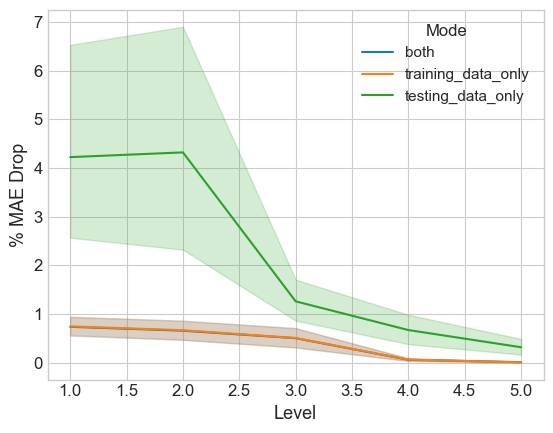

In [309]:
seaborn.lineplot(data=regression_df[regression_df["Method"] == "rounding"], x="Level", y="% MAE Drop", hue="Mode")


<Axes: xlabel='Level', ylabel='% MAE Drop'>

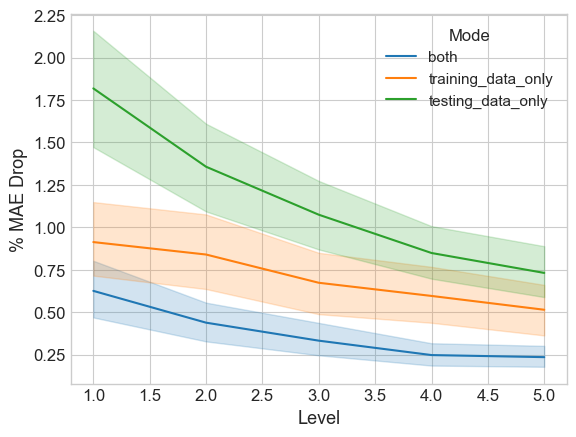

In [310]:
seaborn.lineplot(data=regression_df[regression_df["Method"] == "quantile"], x="Level", y="% MAE Drop", hue="Mode")


<Axes: xlabel='Level', ylabel='% MAE Drop'>

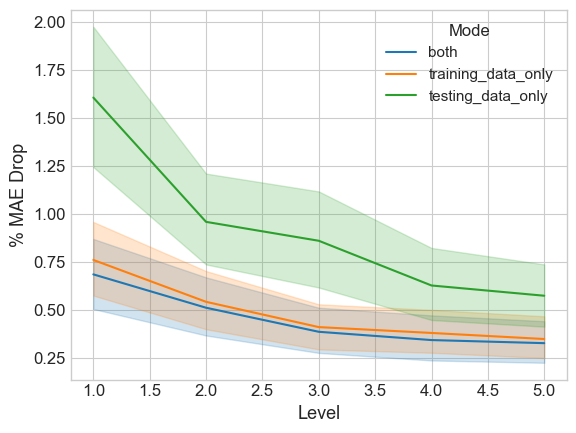

In [311]:
seaborn.lineplot(data=regression_df[regression_df["Method"] == "kmeans"], x="Level", y="% MAE Drop", hue="Mode")


<Axes: xlabel='Level', ylabel='% MAE Drop'>

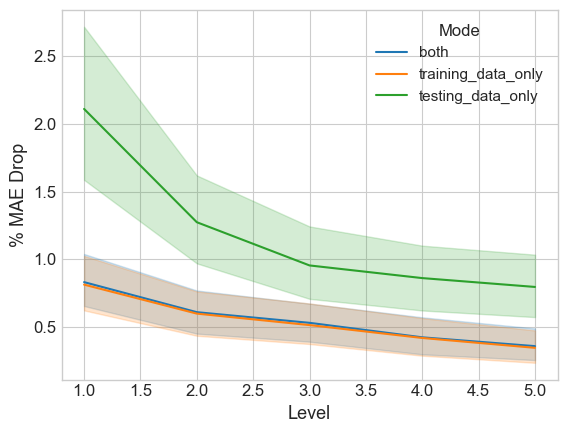

In [312]:
seaborn.lineplot(data=regression_df[regression_df["Method"] == "uniform"], x="Level", y="% MAE Drop", hue="Mode")


<Axes: xlabel='Level', ylabel='% MAE Drop'>

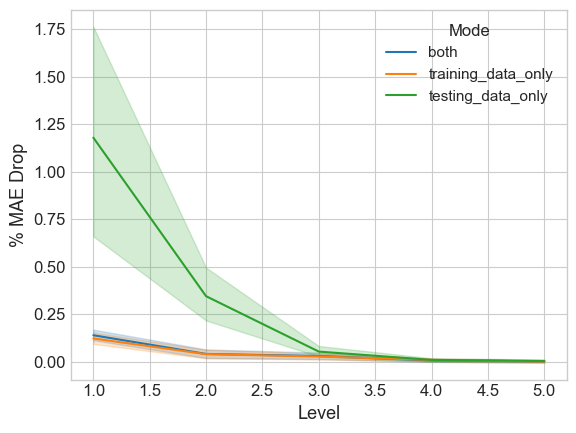

In [313]:
seaborn.lineplot(data=regression_df[regression_df["Method"] == "sig figs"], x="Level", y="% MAE Drop", hue="Mode")


<Axes: xlabel='Level', ylabel='MAE'>

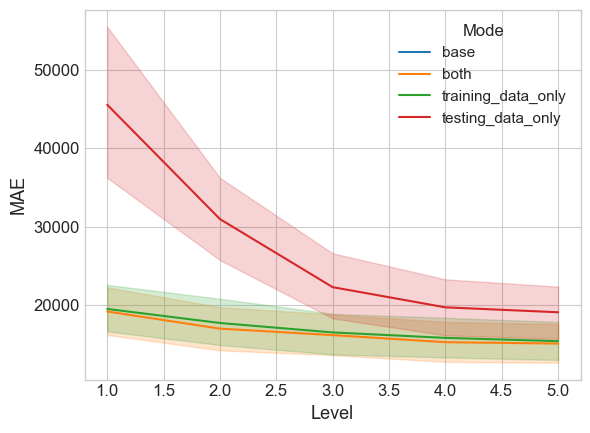

In [314]:
seaborn.lineplot(data=regression_df, x="Level", y="MAE", hue="Mode")



In [382]:

pivot = classification_df[classification_df["Method"] != "base"].groupby(["Mode","Level"])["% Accuracy Drop"].mean().unstack()
pivot2 = regression_df[regression_df["Method"] != "base"].groupby(["Mode","Level"])["% MAE Drop"].mean().unstack()
pivot = pivot.loc[["both","training_data_only","testing_data_only"]]
pivot2 = pivot2.loc[["both","training_data_only","testing_data_only"]]

pivot

Level,1,2,3,4,5
Mode,,,,,
both,0.100535,0.051907,0.028557,0.018435,0.010319
training_data_only,0.205334,0.098455,0.064337,0.041623,0.015882
testing_data_only,0.335922,0.211781,0.159522,0.106651,0.072617


Text(0.5, 1.0, '% Drop in Accuracy | Mode & Level | Classification')

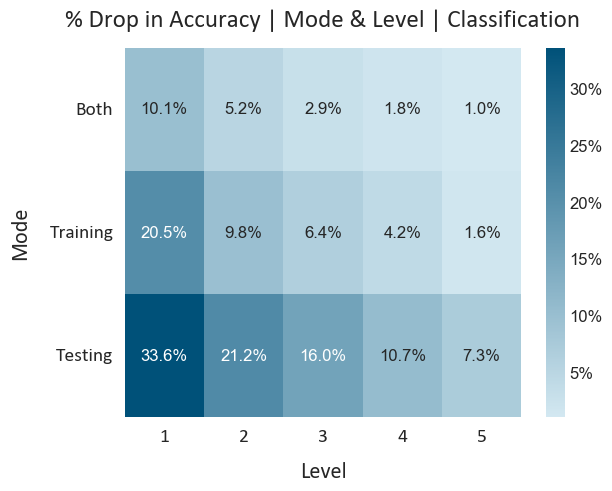

In [404]:

seaborn.heatmap(pivot, yticklabels=["Both", "Training", "Testing"],annot=True, cmap=cool_blue_cmap, fmt='.1%', cbar_kws={'format': mticker.PercentFormatter(1.0, decimals=0)}).tick_params(axis='both', pad=8)
plt.xlabel("Level", fontsize=16, labelpad=12, fontdict=axis_font)
plt.yticks(rotation=0,fontname='Calibri', fontsize=14)
plt.xticks(rotation=0,fontname='Calibri', fontsize=14)
plt.ylabel("Mode", fontsize=16, labelpad=14, fontdict=axis_font)
plt.title("% Drop in Accuracy | Mode & Level | Classification", fontsize=18, pad=15, fontdict=title_font)


Text(0.5, 1.0, '% Increase in MAE | Mode & Level | Regression')

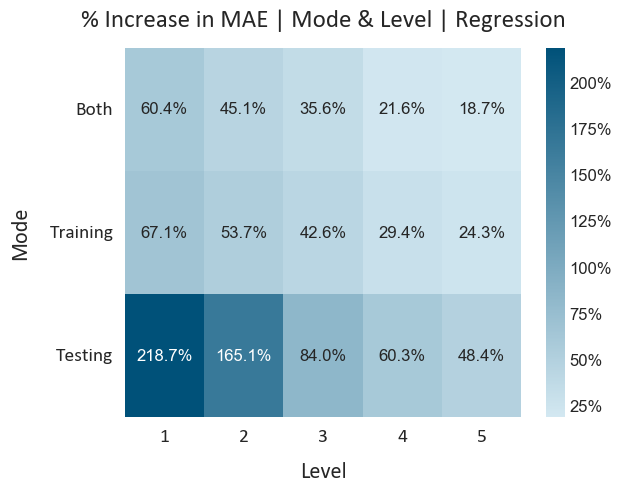

In [403]:

seaborn.heatmap(pivot2, yticklabels=["Both", "Training", "Testing"],annot=True, cmap=cool_blue_cmap, fmt='.1%', cbar_kws={'format': mticker.PercentFormatter(1.0, decimals=0)}).tick_params(axis='both', pad=8)
plt.xlabel("Level", fontsize=16, labelpad=12, fontdict=axis_font)
plt.yticks(rotation=0,fontname='Calibri', fontsize=14)
plt.xticks(rotation=0,fontname='Calibri', fontsize=14)
plt.ylabel("Mode", fontsize=16, labelpad=14, fontdict=axis_font)
plt.title("% Increase in MAE | Mode & Level | Regression", fontsize=18, pad=15, fontdict=title_font)


<Axes: xlabel='Method'>

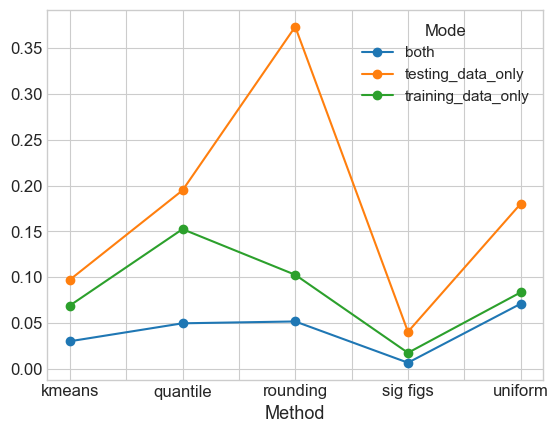

In [318]:
classification_df[classification_df["Method"] != "base"].groupby(["Method","Mode"])["% Accuracy Drop"].mean().unstack().plot(marker='o')

Text(0.5, 1.0, '% Drop in Accuracy | Method & Level | Classification')

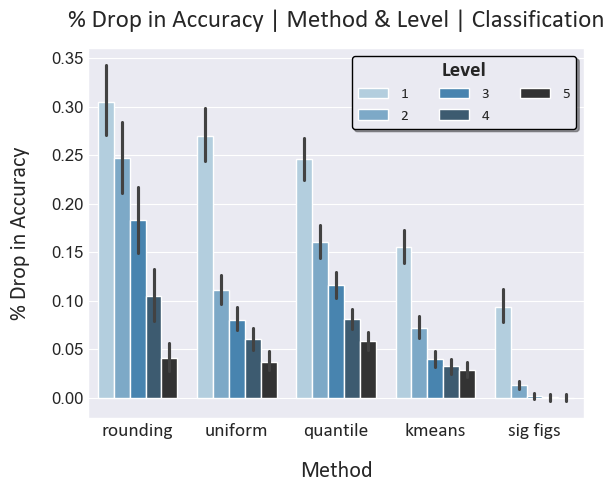

In [319]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=classification_df_level_1to5[classification_df_level_1to5["Method"]!="base"], x="Method", y="% Accuracy Drop", hue="Level", palette="Blues_d")
plt.xlabel("Method", fontsize=16, labelpad=16, fontdict=axis_font) 
plt.ylabel("% Drop in Accuracy", fontsize=16, labelpad=15, fontdict=axis_font)
plt.xticks(fontname='Calibri', fontsize=14)
plt.legend(
    title='Level',             # The Header
    title_fontproperties={
        'family': 'Calibri', 
        'size': 15, 
        'weight': 'bold'                 # Makes header stand out
    },
    ncol=3,
    loc="upper right",
    prop={'family': 'Calibri', 'size': 11}, # The sublabels
    frameon=True,                        # The Outline
    edgecolor='black',                   # Outline color
    framealpha=1,                        # Make background solid (not see-through)
    shadow=True                          # Optional: adds a slight drop shadow
)
plt.title("% Drop in Accuracy | Method & Level | Classification", fontsize=18, pad=15, fontdict=title_font)

Text(0.5, 1.0, '% Increase in MAE | Method & Level | Regression')

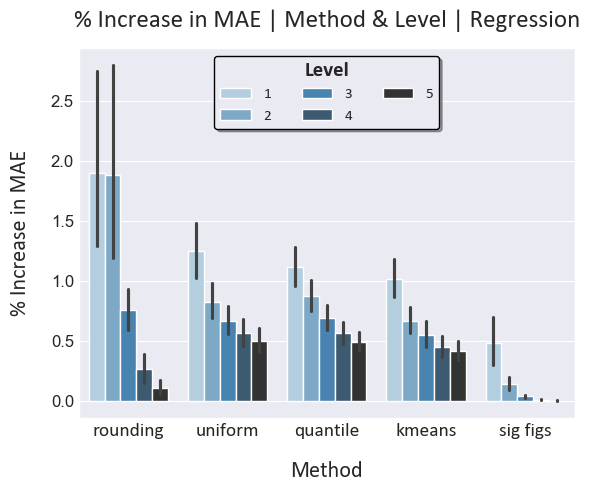

In [320]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=regression_df_level_1to5[regression_df_level_1to5["Method"]!="base"], x="Method", y="% MAE Drop", hue="Level", palette="Blues_d")
plt.xlabel("Method", fontsize=16, labelpad=16, fontdict=axis_font) 
plt.ylabel("% Increase in MAE", fontsize=16, labelpad=15, fontdict=axis_font)
plt.xticks(fontname='Calibri', fontsize=14)
plt.legend(
    title='Level',             # The Header
    title_fontproperties={
        'family': 'Calibri', 
        'size': 15, 
        'weight': 'bold'                 # Makes header stand out
    },
    ncol=3,
    loc="upper center",
    prop={'family': 'Calibri', 'size': 11}, # The sublabels
    frameon=True,                        # The Outline
    edgecolor='black',                   # Outline color
    framealpha=1,                        # Make background solid (not see-through)
    shadow=True                          # Optional: adds a slight drop shadow
)
plt.title("% Increase in MAE | Method & Level | Regression", fontsize=18, pad=15, fontdict=title_font)

In [406]:
classification_df

,Task,Dataset,Seed,Method,Model,Level,Mode,Accuracy,OriginalLevel,base_acc,% Accuracy Drop
0,classification,bc,42,base,logreg,<NA>,base,0.973684,NaN,0.973684,-1.140229e-16
1,classification,bc,42,rounding,logreg,1,both,0.938596,-2.0,0.973684,3.603604e-02
2,classification,bc,42,rounding,logreg,1,training_data_only,0.938596,-2.0,0.973684,3.603604e-02
3,classification,bc,42,rounding,logreg,1,testing_data_only,0.622807,-2.0,0.973684,3.603604e-01
4,classification,bc,42,rounding,logreg,2,both,0.964912,-1.0,0.973684,9.009009e-03
...,...,...,...,...,...,...,...,...,...,...,...
5695,classification,wq_class,100,sig figs,rfc,4,training_data_only,0.740625,4.0,0.701250,-5.614973e-02
5696,classification,wq_class,100,sig figs,rfc,4,testing_data_only,0.709375,4.0,0.701250,-1.158645e-02
5697,classification,wq_class,100,sig figs,rfc,5,both,0.718750,5.0,0.701250,-2.495544e-02
5698,classification,wq_class,100,sig figs,rfc,5,training_data_only,0.734375,5.0,0.701250,-4.723708e-02


Text(0.5, 1.0, '% Increase in MAE | Method & Level | Regression')

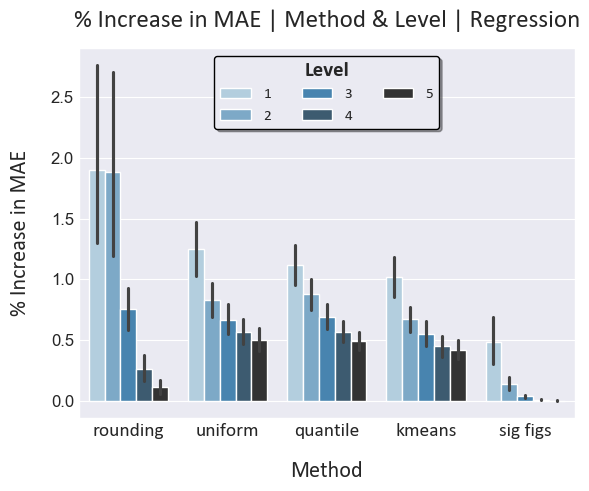

In [405]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=regression_df[regression_df["Method"]!="base"], x="Method", y="% MAE Drop", hue="Level", palette="Blues_d")
plt.xlabel("Method", fontsize=16, labelpad=16, fontdict=axis_font) 
plt.ylabel("% Increase in MAE", fontsize=16, labelpad=15, fontdict=axis_font)
plt.xticks(fontname='Calibri', fontsize=14)
plt.legend(
    title='Level',             # the header
    title_fontproperties={
        'family': 'Calibri', 
        'size': 15, 
        'weight': 'bold'                 # Makes header stand out
    },
    ncol=3,
    loc="upper center",
    prop={'family': 'Calibri', 'size': 11}, # The sublabels
    frameon=True,                        # The Outline
    edgecolor='black',                   # Outline color
    framealpha=1,                        # Make background solid (not see-through)
    shadow=True                          # drop shadow
)
plt.title("% Increase in MAE | Method & Level | Regression", fontsize=18, pad=15, fontdict=title_font)

C:\Users\abelg\AppData\Local\Temp\ipykernel_23000\1365537828.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  seaborn.barplot(data=regression_df[regression_df["Method"]!="base"], x="Model", y="% MAE Drop", palette="Blues_d")


Text(0.5, 1.0, '% Drop in Accuracy | Model | Regression')

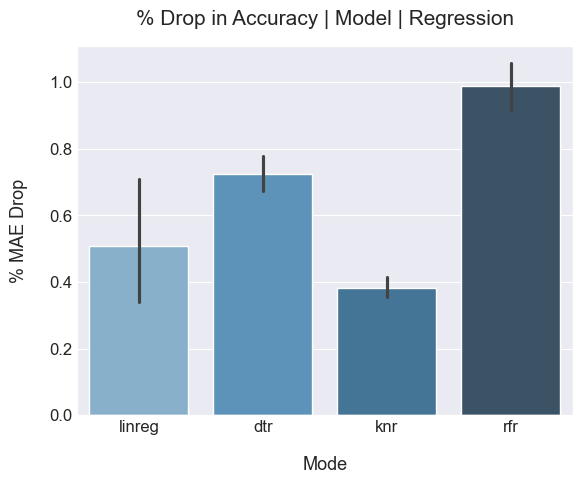

In [322]:
seaborn.barplot(data=regression_df[regression_df["Method"]!="base"], x="Model", y="% MAE Drop", palette="Blues_d")
plt.xlabel("Mode", fontsize=13, labelpad=15) 
plt.ylabel("% MAE Drop", fontsize=13, labelpad=15)

plt.title("% Drop in Accuracy | Model | Regression", fontsize=15, pad=15)

<Axes: xlabel='Mode', ylabel='% Accuracy Drop'>

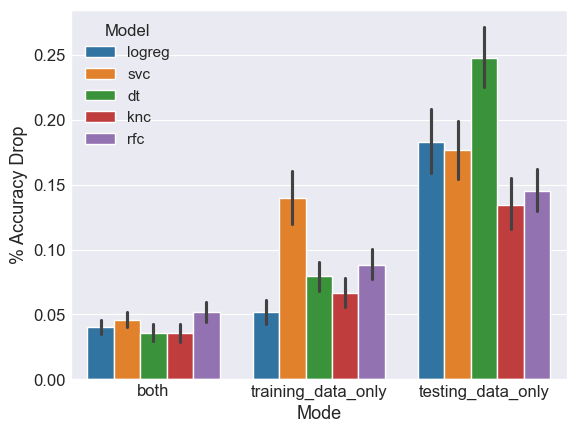

In [323]:
seaborn.barplot(data=classification_df[classification_df["Method"]!="base"], x="Mode", y="% Accuracy Drop", hue="Model")


Text(0.5, 1.0, '% Drop in Accuracy | Mode & Method | Classification')

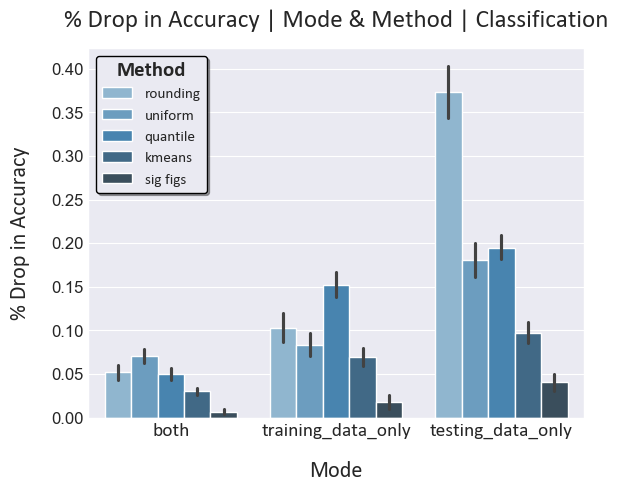

In [324]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=classification_df[classification_df["Method"]!="base"], x="Mode", y="% Accuracy Drop", hue="Method", palette="Blues_d")
plt.xlabel("Mode", fontsize=16, labelpad=16, fontdict=axis_font) 
plt.ylabel("% Drop in Accuracy", fontsize=16, labelpad=15, fontdict=axis_font)
plt.xticks(fontname='Calibri', fontsize=14)
plt.legend(
    title='Method',             # The Header
    title_fontproperties={
        'family': 'Calibri', 
        'size': 15, 
        'weight': 'bold'                 # Makes header stand out
    },
    loc="upper left",
    prop={'family': 'Calibri', 'size': 11}, # The sublabels
    frameon=True,                        # The Outline
    edgecolor='black',                   # Outline color
    framealpha=1,                        # Make background solid (not see-through)
    shadow=True                          # Optional: adds a slight drop shadow
)
plt.title("% Drop in Accuracy | Mode & Method | Classification", fontsize=18, pad=15, fontdict=title_font)

Text(0.5, 1.0, '% Increase in MAE | Mode & Method | Regression')

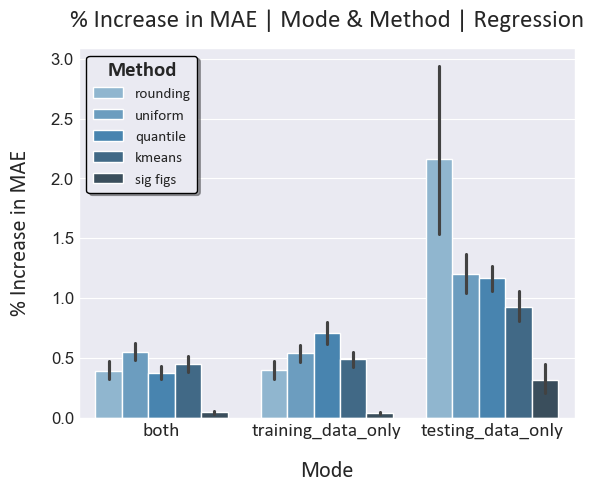

In [325]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=regression_df[regression_df["Method"]!="base"], x="Mode", y="% MAE Drop", hue="Method", palette="Blues_d")
plt.xlabel("Mode", fontsize=16, labelpad=16, fontdict=axis_font) 
plt.ylabel("% Increase in MAE", fontsize=16, labelpad=15, fontdict=axis_font)
plt.xticks(fontname='Calibri', fontsize=14)
plt.legend(
    title='Method',             # The Header
    title_fontproperties={
        'family': 'Calibri', 
        'size': 15, 
        'weight': 'bold'                 # Makes header stand out
    },
    loc="upper left",
    prop={'family': 'Calibri', 'size': 11}, # The sublabels
    frameon=True,                        # The Outline
    edgecolor='black',                   # Outline color
    framealpha=1,                        # Make background solid (not see-through)
    shadow=True                          # Optional: adds a slight drop shadow
)
plt.title("% Increase in MAE | Mode & Method | Regression", fontsize=18, pad=15, fontdict=title_font)

Text(0.5, 1.0, '% Increase in MAE | Mode & Method | Regression')

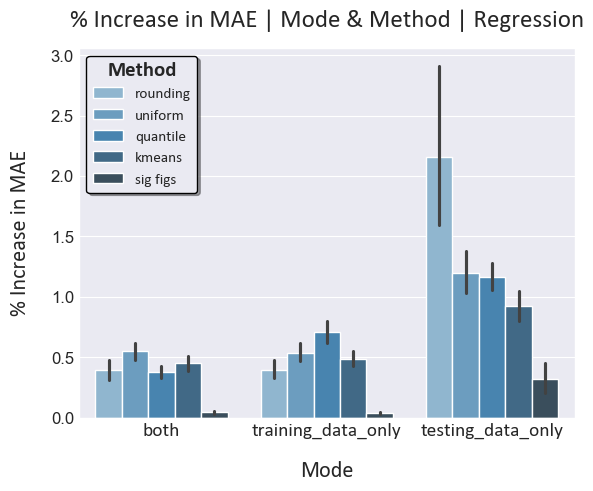

In [326]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=regression_df[regression_df["Method"]!="base"], x="Mode", y="% MAE Drop", hue="Method", palette="Blues_d")
plt.xlabel("Mode", fontsize=16, labelpad=16, fontdict=axis_font) 
plt.ylabel("% Increase in MAE", fontsize=16, labelpad=15, fontdict=axis_font)
plt.xticks(fontname='Calibri', fontsize=14)
plt.legend(
    title='Method',             # The Header
    title_fontproperties={
        'family': 'Calibri', 
        'size': 15, 
        'weight': 'bold'                 # Makes header stand out
    },
    loc="upper left",
    prop={'family': 'Calibri', 'size': 11}, # The sublabels
    frameon=True,                        # The Outline
    edgecolor='black',                   # Outline color
    framealpha=1,                        # Make background solid (not see-through)
    shadow=True                          # Optional: adds a slight drop shadow
)
plt.title("% Increase in MAE | Mode & Method | Regression", fontsize=18, pad=15, fontdict=title_font)

In [523]:
main_effects = biggie_anova[biggie_anova["Source"].isin(["Dataset","Method","Model","Mode","Level"])]
main_effects2 = biggie_anova2[biggie_anova["Source"].isin(["Dataset","Method","Model","Mode","Level"])]
all_main_effects = pd.concat([main_effects,main_effects2]).reset_index(drop=True)
all_main_effects.insert(0, 'Task', ["C","C","C","C","C","R","R","R","R","R"])
all_main_effects

,Task,Source,SS,DF,MS,F,p_unc,np2,partial_omega_sq
0,C,Dataset,10.462708,2.0,5.231354,2701.306176,0.000000e+00,0.545574,0.545317
1,C,Method,16.069429,4.0,4.017357,2074.436582,0.000000e+00,0.648376,0.648012
2,C,Model,1.573562,4.0,0.393391,203.134497,2.170356e-160,0.152947,0.152166
3,C,Mode,17.924335,2.0,8.962167,4627.780658,0.000000e+00,0.672860,0.672665
4,C,Level,22.636475,4.0,5.659119,2922.190514,0.000000e+00,0.722029,0.721738
5,R,Dataset,427.153075,2.0,213.576537,229.073680,2.261715e-94,0.112896,0.112375
6,R,Method,360.686169,4.0,90.171542,96.714402,2.843604e-78,0.097033,0.096006
7,R,Model,238.326347,3.0,79.442116,85.206446,2.935291e-53,0.066298,0.065503
8,R,Mode,573.415745,2.0,286.707873,307.511434,5.065450e-124,0.145912,0.145403
9,R,Level,464.266992,4.0,116.066748,124.488567,1.163011e-99,0.121513,0.120507


In [ ]:
regression_nonbase_newwww

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,OriginalLevel,base_MAE,acc_drop
1,regression,ch,42,rounding,linreg,1,both,68021.055442,0.395945,8.260559e+09,-2.0,50079.474365,0.358262
2,regression,ch,42,rounding,linreg,1,training_data_only,71229.080523,0.389339,8.350896e+09,-2.0,50079.474365,0.422321
3,regression,ch,42,rounding,linreg,1,testing_data_only,205303.662399,-2.663042,5.009276e+10,-2.0,50079.474365,3.099557
4,regression,ch,42,rounding,linreg,2,both,60265.427026,0.534080,6.371545e+09,-1.0,50079.474365,0.203396
5,regression,ch,42,rounding,linreg,2,training_data_only,66694.748900,0.489634,6.979347e+09,-1.0,50079.474365,0.331778
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4,training_data_only,0.418250,0.434741,3.547000e-01,4.0,0.416944,0.003133
4556,regression,wq_reg,100,sig figs,rfr,4,testing_data_only,0.415094,0.435262,3.543728e-01,4.0,0.416944,-0.004437
4557,regression,wq_reg,100,sig figs,rfr,5,both,0.417500,0.438672,3.522331e-01,5.0,0.416944,0.001334
4558,regression,wq_reg,100,sig figs,rfr,5,training_data_only,0.414000,0.449369,3.455213e-01,5.0,0.416944,-0.007060


C:\Users\abelg\AppData\Local\Temp\ipykernel_23000\1626231501.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  seaborn.barplot(data=main_effects2, x="Source", y="partial_omega_sq", palette="Blues_d")


Text(0.5, 1.0, 'Effect Size Across Independent Variables | Regression')

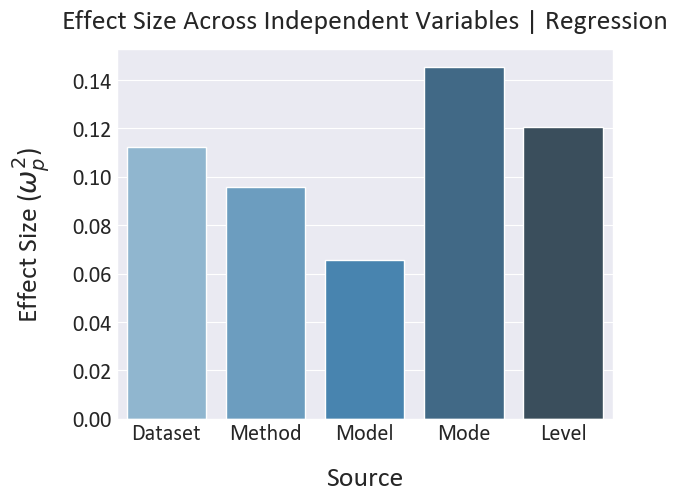

In [549]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=main_effects2, x="Source", y="partial_omega_sq", palette="Blues_d")
plt.xlabel("Source", fontsize=20, labelpad=16, fontdict=axis_font) 
plt.ylabel(f"Effect Size ({r"$\omega_p^2$"})", fontsize=20, labelpad=15, fontdict=axis_font)
# plt.ylim(0,.75)
plt.xticks(fontname='Calibri', fontsize=16)
plt.yticks(fontname='Calibri', fontsize=16)
# plt.legend(
#     title='Method',             # The Header
#     title_fontproperties={
#         'family': 'Calibri', 
#         'size': 15, 
#         'weight': 'bold'                 # Makes header stand out
#     },
#     loc="upper left",
#     prop={'family': 'Calibri', 'size': 11}, # The sublabels
#     frameon=True,                        # The Outline
#     edgecolor='black',                   # Outline color
#     framealpha=1,                        # Make background solid (not see-through)
#     shadow=True                          # Optional: adds a slight drop shadow
# )
plt.title("Effect Size Across Independent Variables | Regression", fontsize=20, pad=15, fontdict=title_font)

C:\Users\abelg\AppData\Local\Temp\ipykernel_23000\4260087009.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  seaborn.barplot(data=classification_df[classification_df["Method"]!="base"], x="Mode", y="% Accuracy Drop", palette="Blues_d")


Text(0.5, 1.0, 'Drop in Accuracy | Mode | Classification')

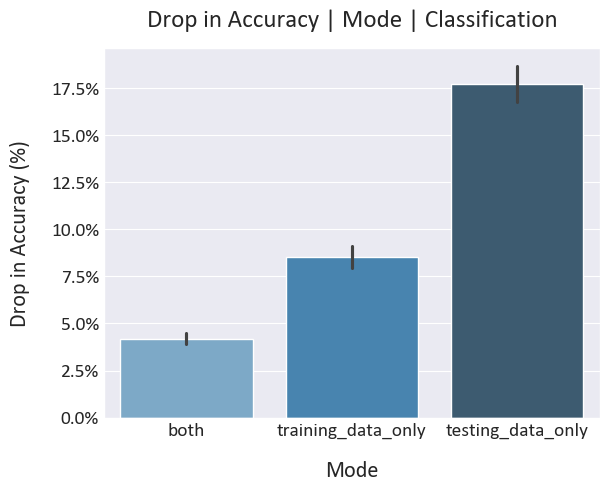

In [539]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=classification_df[classification_df["Method"]!="base"], x="Mode", y="% Accuracy Drop", palette="Blues_d")
plt.xlabel("Mode", fontsize=16, labelpad=16, fontdict=axis_font) 
plt.ylabel("Drop in Accuracy (%)", fontsize=16, labelpad=15, fontdict=axis_font)
plt.xticks(fontname='Calibri', fontsize=14)
plt.yticks(fontname='Calibri', fontsize=14)
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, symbol="%"))

# plt.legend(
#     title='Model',             # The Header
#     title_fontproperties={
#         'family': 'Calibri', 
#         'size': 15, 
#         'weight': 'bold'                 # Makes header stand out
#     },
#     loc="upper left",
#     prop={'family': 'Calibri', 'size': 11}, # The sublabels
#     frameon=True,                        # The Outline
#     edgecolor='black',                   # Outline color
#     framealpha=1,                        # Make background solid (not see-through)
#     shadow=True                          # Optional: adds a slight drop shadow
# )
plt.title("Drop in Accuracy | Mode | Classification", fontsize=18, pad=15, fontdict=title_font)

C:\Users\abelg\AppData\Local\Temp\ipykernel_23000\1337205903.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  seaborn.barplot(data=regression_df[regression_df["Method"]!="base"], x="Mode", y="% MAE Drop", palette="Blues_d")


Text(0.5, 1.0, 'Drop in Accuracy | Mode | Regression')

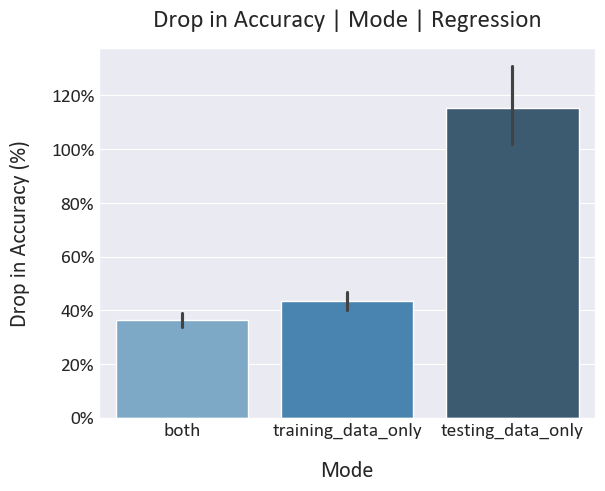

In [463]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=regression_df[regression_df["Method"]!="base"], x="Mode", y="% MAE Drop", palette="Blues_d")
plt.xlabel("Mode", fontsize=16, labelpad=16, fontdict=axis_font) 
plt.ylabel("Drop in Accuracy (%)", fontsize=16, labelpad=15, fontdict=axis_font)
plt.xticks(fontname='Calibri', fontsize=14)
plt.yticks(fontname='Calibri', fontsize=14)
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, symbol="%"))

# plt.legend(
#     title='Model',             # The Header
#     title_fontproperties={
#         'family': 'Calibri', 
#         'size': 15, 
#         'weight': 'bold'                 # Makes header stand out
#     },
#     loc="upper left",
#     prop={'family': 'Calibri', 'size': 11}, # The sublabels
#     frameon=True,                        # The Outline
#     edgecolor='black',                   # Outline color
#     framealpha=1,                        # Make background solid (not see-through)
#     shadow=True                          # Optional: adds a slight drop shadow
# )
plt.title("Drop in Accuracy | Mode | Regression", fontsize=18, pad=15, fontdict=title_font)

C:\Users\abelg\AppData\Local\Temp\ipykernel_23000\672100121.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  seaborn.barplot(data=classification_df[classification_df["Method"]!="base"], x="Method", y="% Accuracy Drop", palette="Blues_d")


Text(0.5, 1.0, 'Drop in Accuracy | Method | Classification')

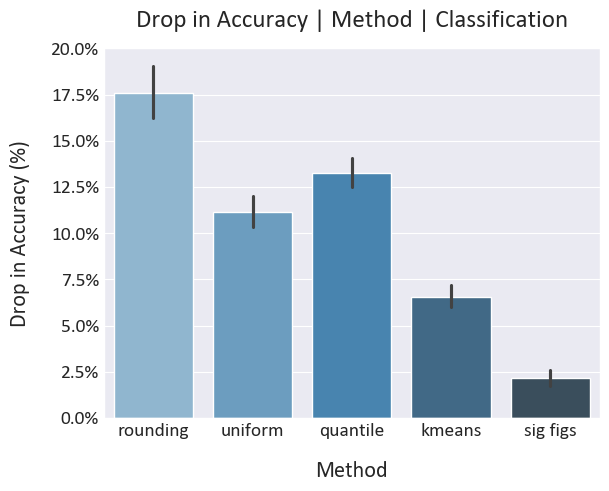

In [470]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=classification_df[classification_df["Method"]!="base"], x="Method", y="% Accuracy Drop", palette="Blues_d")
plt.xlabel("Method", fontsize=16, labelpad=16, fontdict=axis_font) 
plt.ylabel("Drop in Accuracy (%)", fontsize=16, labelpad=15, fontdict=axis_font)
plt.xticks(fontname='Calibri', fontsize=14)
plt.yticks(fontname='Calibri', fontsize=14)
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, symbol="%"))

# plt.legend(
#     title='Model',             # The Header
#     title_fontproperties={
#         'family': 'Calibri', 
#         'size': 15, 
#         'weight': 'bold'                 # Makes header stand out
#     },
#     loc="upper left",
#     prop={'family': 'Calibri', 'size': 11}, # The sublabels
#     frameon=True,                        # The Outline
#     edgecolor='black',                   # Outline color
#     framealpha=1,                        # Make background solid (not see-through)
#     shadow=True                          # Optional: adds a slight drop shadow
# )
plt.title("Drop in Accuracy | Method | Classification", fontsize=18, pad=15, fontdict=title_font)

In [ ]:
regression_nonbase_newwww

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,OriginalLevel,base_MAE,acc_drop
1,regression,ch,42,rounding,linreg,1,both,68021.055442,0.395945,8.260559e+09,-2.0,50079.474365,0.358262
2,regression,ch,42,rounding,linreg,1,training_data_only,71229.080523,0.389339,8.350896e+09,-2.0,50079.474365,0.422321
3,regression,ch,42,rounding,linreg,1,testing_data_only,205303.662399,-2.663042,5.009276e+10,-2.0,50079.474365,3.099557
4,regression,ch,42,rounding,linreg,2,both,60265.427026,0.534080,6.371545e+09,-1.0,50079.474365,0.203396
5,regression,ch,42,rounding,linreg,2,training_data_only,66694.748900,0.489634,6.979347e+09,-1.0,50079.474365,0.331778
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4,training_data_only,0.418250,0.434741,3.547000e-01,4.0,0.416944,0.003133
4556,regression,wq_reg,100,sig figs,rfr,4,testing_data_only,0.415094,0.435262,3.543728e-01,4.0,0.416944,-0.004437
4557,regression,wq_reg,100,sig figs,rfr,5,both,0.417500,0.438672,3.522331e-01,5.0,0.416944,0.001334
4558,regression,wq_reg,100,sig figs,rfr,5,training_data_only,0.414000,0.449369,3.455213e-01,5.0,0.416944,-0.007060


C:\Users\abelg\AppData\Local\Temp\ipykernel_23000\1428595369.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  seaborn.barplot(data=regression_df[regression_df["Method"]!="base"], x="Method", y="% MAE Drop", palette="Blues_d")


Text(0.5, 1.0, 'Increase in MAE | Method | Regression')

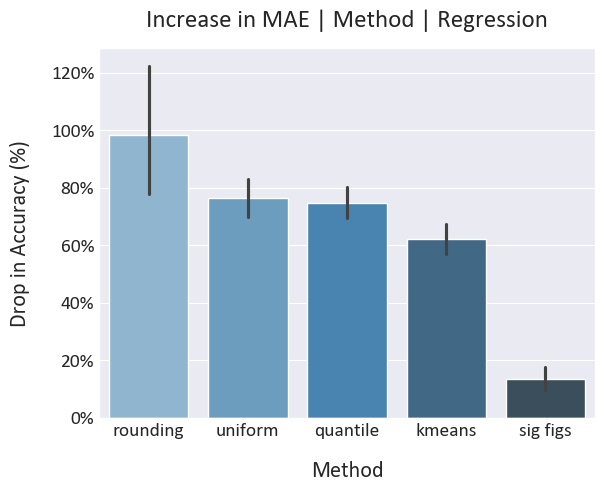

In [469]:

seaborn.set_style("darkgrid")
seaborn.barplot(data=regression_df[regression_df["Method"]!="base"], x="Method", y="% MAE Drop", palette="Blues_d")
plt.xlabel("Method", fontsize=16, labelpad=16, fontdict=axis_font) 
plt.ylabel("Drop in Accuracy (%)", fontsize=16, labelpad=15, fontdict=axis_font)
plt.xticks(fontname='Calibri', fontsize=14)
plt.yticks(fontname='Calibri', fontsize=14)
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, symbol="%"))

# plt.legend(
#     title='Model',             # The Header
#     title_fontproperties={
#         'family': 'Calibri', 
#         'size': 15, 
#         'weight': 'bold'                 # Makes header stand out
#     },
#     loc="upper left",
#     prop={'family': 'Calibri', 'size': 11}, # The sublabels
#     frameon=True,                        # The Outline
#     edgecolor='black',                   # Outline color
#     framealpha=1,                        # Make background solid (not see-through)
#     shadow=True                          # Optional: adds a slight drop shadow
# )
plt.title("Increase in MAE | Method | Regression", fontsize=18, pad=15, fontdict=title_font)

<Axes: xlabel='Source'>

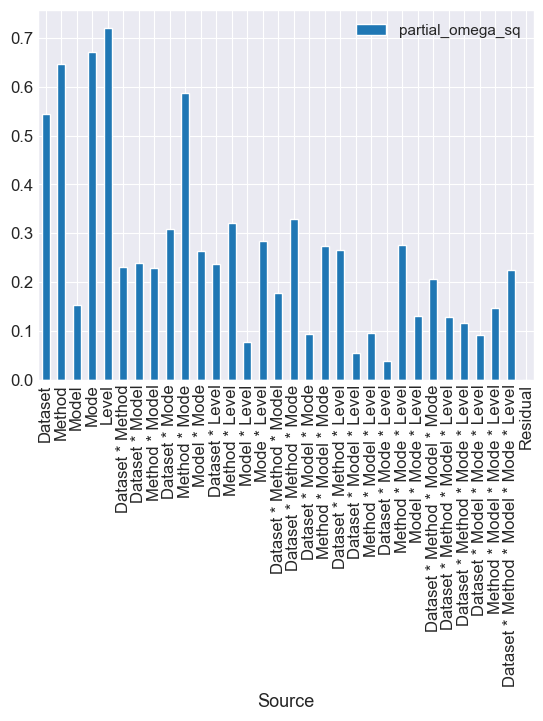

In [473]:
biggie_anova.plot.bar(x="Source", y="partial_omega_sq")

In [480]:
#POSTHOC
pingouin.pairwise_tukey(data=classification_df,dv="% Accuracy Drop",between="Mode")

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,base,both,-9.714451e-19,0.041951,-0.041951,0.017787,-2.358503,0.085374,-0.640592
1,base,testing_data_only,-9.714451e-19,0.177299,-0.177299,0.017787,-9.967883,0.000000,-0.838090
2,base,training_data_only,-9.714451e-19,0.085126,-0.085126,0.017787,-4.785875,0.000010,-0.638441
3,both,testing_data_only,4.195066e-02,0.177299,-0.135348,0.004933,-27.436011,0.000000,-0.848395
4,both,training_data_only,4.195066e-02,0.085126,-0.043176,0.004933,-8.752014,0.000000,-0.403741
5,testing_data_only,training_data_only,1.772986e-01,0.085126,0.092172,0.004933,18.683998,0.000000,0.511598


In [482]:
#POSTHOC
pingouin.pairwise_tukey(data=regression_df,dv="% MAE Drop",between="Mode")

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,base,both,-1.202742e-17,0.362792,-0.362792,0.226085,-1.604671,0.376016,-0.668042
1,base,testing_data_only,-1.202742e-17,1.153261,-1.153261,0.226085,-5.101002,0.000002,-0.409234
2,base,training_data_only,-1.202742e-17,0.434322,-0.434322,0.226085,-1.921052,0.219256,-0.690879
3,both,testing_data_only,3.627924e-01,1.153261,-0.790469,0.062705,-12.606202,0.000000,-0.382160
4,both,training_data_only,3.627924e-01,0.434322,-0.071529,0.062705,-1.140730,0.664269,-0.119474
5,testing_data_only,training_data_only,1.153261e+00,0.434322,0.718940,0.062705,11.465472,0.000000,0.345482


In [478]:

pingouin.pairwise_tukey(data=classification_nonbase_newwww,dv="acc_drop",between="Mode")

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,both,testing_data_only,0.041951,0.177299,-0.135348,0.004965,-27.262884,2.187805e-12,-0.848395
1,both,training_data_only,0.041951,0.085126,-0.043176,0.004965,-8.696786,2.187805e-12,-0.403741
2,testing_data_only,training_data_only,0.177299,0.085126,0.092172,0.004965,18.566097,2.187805e-12,0.511598


In [483]:

pingouin.pairwise_tukey(data=regression_nonbase_newwww,dv="acc_drop",between="Mode")

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,both,testing_data_only,0.362792,1.153261,-0.790469,0.063115,-12.524337,9.193757e-13,-0.382160
1,both,training_data_only,0.362792,0.434322,-0.071529,0.063115,-1.133322,4.935484e-01,-0.119474
2,testing_data_only,training_data_only,1.153261,0.434322,0.718940,0.063115,11.391015,9.193757e-13,0.345482


In [521]:

pingouin.pairwise_tukey(data=regression_nonbase_newwww,dv="acc_drop",between="Model")

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,dtr,knr,0.722914,0.382057,0.340858,0.07379,4.619299,2.347826e-05,0.465128
1,dtr,linreg,0.722914,0.507328,0.215587,0.07379,2.921627,1.837198e-02,0.094349
2,dtr,rfr,0.722914,0.988201,-0.265287,0.07379,-3.595165,1.860195e-03,-0.243265
3,knr,linreg,0.382057,0.507328,-0.125271,0.07379,-1.697672,3.249656e-01,-0.056360
4,knr,rfr,0.382057,0.988201,-0.606145,0.07379,-8.214464,0.000000e+00,-0.635954
5,linreg,rfr,0.507328,0.988201,-0.480874,0.07379,-6.516792,4.748308e-10,-0.203340


In [ ]:
regression_nonbase_newwww

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,OriginalLevel,base_MAE,acc_drop
1,regression,ch,42,rounding,linreg,1,both,68021.055442,0.395945,8.260559e+09,-2.0,50079.474365,0.358262
2,regression,ch,42,rounding,linreg,1,training_data_only,71229.080523,0.389339,8.350896e+09,-2.0,50079.474365,0.422321
3,regression,ch,42,rounding,linreg,1,testing_data_only,205303.662399,-2.663042,5.009276e+10,-2.0,50079.474365,3.099557
4,regression,ch,42,rounding,linreg,2,both,60265.427026,0.534080,6.371545e+09,-1.0,50079.474365,0.203396
5,regression,ch,42,rounding,linreg,2,training_data_only,66694.748900,0.489634,6.979347e+09,-1.0,50079.474365,0.331778
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4,training_data_only,0.418250,0.434741,3.547000e-01,4.0,0.416944,0.003133
4556,regression,wq_reg,100,sig figs,rfr,4,testing_data_only,0.415094,0.435262,3.543728e-01,4.0,0.416944,-0.004437
4557,regression,wq_reg,100,sig figs,rfr,5,both,0.417500,0.438672,3.522331e-01,5.0,0.416944,0.001334
4558,regression,wq_reg,100,sig figs,rfr,5,training_data_only,0.414000,0.449369,3.455213e-01,5.0,0.416944,-0.007060


In [438]:
groups = [
    classification_nonbase_newwww.loc[classification_nonbase_newwww["Mode"] == mode, "acc_drop"].dropna()
    for mode in classification_nonbase_newwww["Mode"].dropna().unique()
]
print(scipy.stats.tukey_hsd(*groups, equal_var=True).confidence_interval())
scikit_posthocs.posthoc_tukey(classification_nonbase_newwww,"acc_drop","Mode",)

ConfidenceInterval(low=array([[-0.01163851, -0.05481413, -0.14698645],
       [ 0.03153712, -0.01163851, -0.10381082],
       [ 0.12370943,  0.08053381, -0.01163851]]), high=array([[ 0.01163851, -0.03153712, -0.12370943],
       [ 0.05481413,  0.01163851, -0.08053381],
       [ 0.14698645,  0.10381082,  0.01163851]]))


,both,training_data_only,testing_data_only
both,1.000000e+00,2.187805e-12,2.187805e-12
training_data_only,2.187805e-12,1.000000e+00,2.187805e-12
testing_data_only,2.187805e-12,2.187805e-12,1.000000e+00


In [ ]:
regression_nonbase_newwww

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,OriginalLevel,base_MAE,acc_drop
1,regression,ch,42,rounding,linreg,1,both,68021.055442,0.395945,8.260559e+09,-2.0,50079.474365,0.358262
2,regression,ch,42,rounding,linreg,1,training_data_only,71229.080523,0.389339,8.350896e+09,-2.0,50079.474365,0.422321
3,regression,ch,42,rounding,linreg,1,testing_data_only,205303.662399,-2.663042,5.009276e+10,-2.0,50079.474365,3.099557
4,regression,ch,42,rounding,linreg,2,both,60265.427026,0.534080,6.371545e+09,-1.0,50079.474365,0.203396
5,regression,ch,42,rounding,linreg,2,training_data_only,66694.748900,0.489634,6.979347e+09,-1.0,50079.474365,0.331778
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4,training_data_only,0.418250,0.434741,3.547000e-01,4.0,0.416944,0.003133
4556,regression,wq_reg,100,sig figs,rfr,4,testing_data_only,0.415094,0.435262,3.543728e-01,4.0,0.416944,-0.004437
4557,regression,wq_reg,100,sig figs,rfr,5,both,0.417500,0.438672,3.522331e-01,5.0,0.416944,0.001334
4558,regression,wq_reg,100,sig figs,rfr,5,training_data_only,0.414000,0.449369,3.455213e-01,5.0,0.416944,-0.007060


In [417]:
#COMFIRMING ANOVAS WITH STATMODEL LIBRARY ---- THEY BASICALLY MATCHHH 🥹🥹

df = regression_nonbase_newwww.copy()

# Make sure factors are categorical
for col in ["Dataset", "Method", "Model", "Mode", "Level"]:
    df[col] = df[col].astype("category")

# 5-way ANOVA with all interactions
formula = "acc_drop ~ C(Dataset) * C(Method) * C(Model) * C(Mode) * C(Level)"

model = ols(formula, data=df).fit()

anova_table = anova_lm(model, typ=2)

# Calculate partial eta squared
ss_error = anova_table.loc["Residual", "sum_sq"]

anova_table["partial_eta_sq"] = (
    anova_table["sum_sq"] /
    (anova_table["sum_sq"] + ss_error)
)

anova_table.loc["Residual", "partial_eta_sq"] = np.nan

# Calculate partial omega squared
ms_error = anova_table.loc["Residual", "sum_sq"] / anova_table.loc["Residual", "df"]

anova_table["partial_omega_sq"] = (
    (anova_table["sum_sq"] - anova_table["df"] * ms_error) /
    (anova_table["sum_sq"] + ss_error + ms_error)
)

anova_table.loc["Residual", "partial_omega_sq"] = np.nan
anova_table["partial_omega_sq"] = anova_table["partial_omega_sq"].clip(lower=0)

anova_table

,sum_sq,df,F,PR(>F),partial_eta_sq,partial_omega_sq
C(Dataset),427.153075,2.0,229.073680,2.261715e-94,0.112896,0.112375
C(Method),360.686169,4.0,96.714402,2.843604e-78,0.097033,0.096006
C(Model),238.326347,3.0,85.206446,2.935291e-53,0.066298,0.065503
C(Mode),573.415745,2.0,307.511434,5.065450e-124,0.145912,0.145403
C(Level),464.266992,4.0,124.488567,1.163011e-99,0.121513,0.120507
C(Dataset):C(Method),355.559107,8.0,47.669815,1.690634e-73,0.095786,0.093753
C(Dataset):C(Model),623.040195,6.0,111.374679,3.142957e-129,0.156563,0.155121
C(Method):C(Model),260.216598,12.0,23.258162,1.351463e-50,0.071949,0.068838
C(Dataset):C(Mode),2.478980,4.0,0.664714,6.164762e-01,0.000738,0.000000
C(Method):C(Mode),284.717487,8.0,38.172078,1.067648e-58,0.078194,0.076126
